In [ ]:
# pip install tensorflow keras matplotlib numpy

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.applications import VGG16
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
# Normalize pixel values
x_train, x_test = x_train / 255.0, x_test / 255.0
# Convert labels to categorical format
y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

In [ ]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))
# Freeze the pre-trained layers
base_model.trainable = False

In [ ]:
x = Flatten()(base_model.output)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)
output_layer = Dense(10, activation='softmax')(x)
model = Model(inputs=base_model.input, outputs=output_layer)

In [ ]:
model.compile(optimizer='adam',
 loss='categorical_crossentropy',
 metrics=['accuracy'])


In [ ]:
history = model.fit(x_train, y_train,
 epochs=10,
 validation_data=(x_test, y_test),
 batch_size=32)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 766s 489ms/step - accuracy: 0.5293 - loss: 1.3425 - val_accuracy: 0.5611 - val_loss: 1.2490
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 773s 495ms/step - accuracy: 0.5941 - loss: 1.1561 - val_accuracy: 0.5880 - val_loss: 1.1723
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.6193 - loss: 1.0864 - val_accuracy: 0.5969 - val_loss: 1.1518
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 749s 479ms/step - accuracy: 0.6353 - loss: 1.0346 - val_accuracy: 0.6050 - val_loss: 1.1224
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 770s 492ms/step - accuracy: 0.6515 - loss: 0.9879 - val_accuracy: 0.6002 - val_loss: 1.1300
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 768s 492ms/step - accuracy: 0.6655 - loss: 0.9428 - val_accuracy: 0.6127 - val_loss: 1.1310
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 783s 479ms/step - accuracy: 0.6799 - loss: 0.9045 - val_accuracy: 0.6107 - val_loss: 1.1430
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 773s 494ms/step - ac

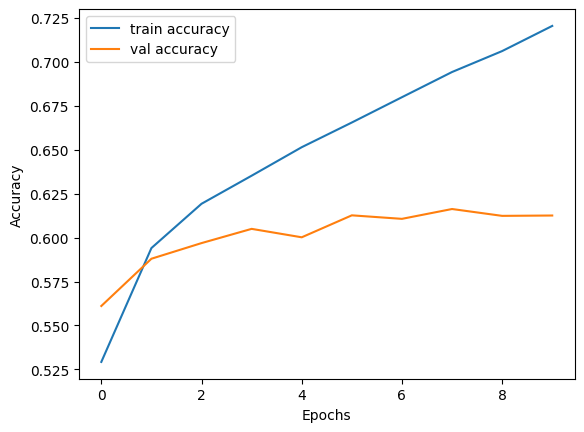

In [ ]:
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

313/313 - 122s - 390ms/step - accuracy: 0.6126 - loss: 1.1595
Test Accuracy: 61.26%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step


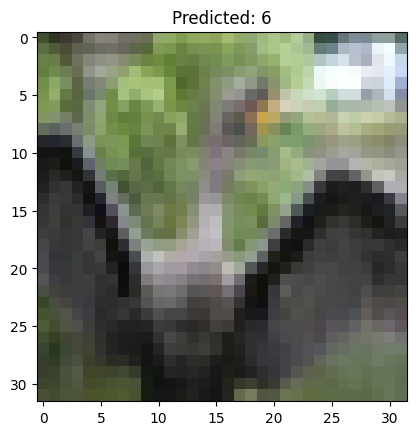

In [ ]:
index = np.random.randint(0, len(x_test))
sample_image = np.expand_dims(x_test[index], axis=0)
prediction = model.predict(sample_image)
predicted_label = np.argmax(prediction)
plt.imshow(x_test[index])
plt.title(f"Predicted: {predicted_label}")
plt.show()